# Valuing the option to store maize in Uasin-Gishu

**Erdős Institute — Quantitative Methods in Finance, Fall 2026 — course project**

> **Inspired by the Zindi [agriBORA Commodity Price Forecasting Challenge](https://zindi.africa/competitions/agribora-commodity-price-forecasting-challenge)**,
> which asked participants to forecast weekly wholesale maize prices in five Kenyan counties
> (scored by RMSE and MAE) using agriBORA's transaction prices and KAMIS market data. This
> project starts from the challenge's setting — the challenge's KAMIS prices fill gaps in the
> longer WFP price series used here — but asks a different, financial question: not *what will the price be*, but *is it worth storing grain to sell
> later, and when?* — the decision that a price forecast is ultimately for.

## Background

**Maize in Kenya.** Maize is Kenya's main staple food, and most of it is grown by smallholder
farmers on the long-rains crop: planted around March–April and harvested from October to
December, with prices lowest at harvest and highest in the lean season, May to August
(agriGHALA policy brief, CIAT/agriBORA 2026). Many farmers sell immediately after harvest —
they need cash and lack safe storage — and on-farm storage losses to insects and rodents have
been estimated at up to ≈ 36% a year (De Groote et al. 2023). Government interventions (cereal
board purchases, import-duty waivers) can move prices sharply in any one season.

**Uasin-Gishu and Eldoret.** Uasin-Gishu county, in the North Rift, is one of Kenya's main
maize-producing areas — with neighbouring Trans-Nzoia it is often described as the country's
grain basket. Its main town, **Eldoret**, is the regional grain-trading centre.

**agriBORA and agriGHALA.** agriBORA is a Kenyan agritech company ("data driven agribusiness").
In December 2024 it opened **agriGHALA** in Eldoret, the first private certified warehouse
under Kenya's Warehouse Receipt System (WRS Act 2019). agriGHALA bundles four services that
were previously separate (agriGHALA policy brief, CIAT / agriBORA / P4G, May 2026):

* **certified storage** — grain is accepted only if graded (moisture ≤ 13.5%, low aflatoxin),
  re-bagged, fumigated and insured against loss;
* **electronic warehouse receipts** registered with the national WRS registry — a legal title
  to the grain that can be traded or pledged;
* **receipt-backed finance** — loans of up to ≈ 70% of the grain's value through partners such
  as the Agricultural Finance Corporation, banks and cooperatives, so farmers can buy inputs
  without selling at harvest;
* **market linkage** — price benchmarks from KOMEX, the national commodity exchange, and help
  selling later in the season.

Revenue comes from storage fees, financing margins and trading commissions; farmer
cooperatives (e.g. Kuona Mbele in Uasin-Gishu) aggregate grain and co-manage satellite stores.
Early results for Q1 2026: 18,669 kg of grain stored, ≈ 2,800 kg of post-harvest loss avoided,
≈ KES 262,000 in gains for depositors, three receipt-backed loans (KES 300,000) repaid in full,
and over 170 farmers trained. The brief's own worked example (2022): KES 3,500 per 90-kg bag
in April against 6,000–6,500 in July, ≈ KES 1,100 per bag in costs, ≈ +40% for the farmer.
**This project asks how much that option to wait is worth in general, not just in one year.**

**Maize prices, 2006–2025.** In the Eldoret wholesale series used here (WFP / KAMIS), the
annual average price rose from ≈ 12–14 KSh/kg in 2006–07 to ≈ 27–38 KSh/kg through most of
2009–2021 — roughly in line with Kenyan inflation — with sharp spikes in drought years:
48.5 KSh/kg in July 2011, 48.4 in June 2017, and a record 90.4 in June 2023 (annual averages
56 in 2022 and 71 in 2023), followed by falls after good harvests (e.g. an average of 22.5 in
2018). Within almost every year the same pattern repeats: low after harvest, high in the lean
season. That predictable swing is what makes storage potentially valuable — and the bad years
are what make it risky.

**Question.** A Uasin-Gishu farmer holding maize after the October–December harvest can sell
now or store it (in agriBORA's certified Eldoret warehouse, or on the farm) and sell at the end
of any later month. Is waiting worth it, when should the grain be sold, and does storing beat
selling at harvest on real Eldoret prices once realistic costs are included?

## The idea in one inequality

Selling later means (a) a different price, (b) waiting for the money, and (c) paying to keep
the grain. Count time $t$ in months after December ($t = 0$ is December) and measure everything
per KSh of the December price $P_0$. Selling at the end of month $t$ is better than selling in
December if

$$ \mathbb{E}\!\left[\frac{P_t}{P_0}\right] e^{-(i + c)\,t/12} \;>\; 1 , $$

where the expectation is over the uncertain future price, $i$ is the interest rate per year (the
cost of waiting for money, below) and $c$ is the holding-cost rate per year (fees + losses). The
factor $e^{-(i+c)\,t/12}$ is exponential decay: money received later is worth less today at rate
$i$, and the grain itself shrinks or costs money to keep at rate $c$. In commodity economics this
comparison is called the **cost of carry**.

The notebook builds this up step by step:

| Step | What it does |
|---|---|
| 1 | Load the price series |
| 2 | Test whether prices really rise after harvest (the seasonal cycle) |
| 3 | Fit a smooth seasonal growth curve to the price changes |
| 4 | Model the random part of price changes and check the model against the data |
| 5 | Check that the seasonal curve predicts prices it has not seen |
| 6 | Solve the "when to sell" problem with the model |
| 7 | Check that solution independently by simulation |
| 8 | Replay the decision on 17 real seasons, using only data available at the time |
| 9 | Find how high costs can go before storing stops paying |

## Notation and inputs

| Symbol | Meaning | Value used | Source |
|---|---|---|---|
| $t$ | time index in **months**. In the storage problem, months after December: $t = 0$ is December, a sale is possible at the end of $t = 1, \dots, 11$ (Jan … Nov); the time in years is $t/12$ | — | — |
| $P_t$ | Eldoret wholesale maize price in month $t$; $P_0$ is the December price at the start of the season | KSh per kg, nominal (not inflation-adjusted) | WFP / KAMIS, 2006-01 → 2025-06 |
| $r_t = \log(P_t/P_{t-1})$ | monthly log return (log of the price ratio) | — | — |
| $m$ | calendar month (Jan … Dec); $m_t$ is the calendar month of month $t$ | — | — |
| harvest level | in Step 2's figure, the average of the December and January prices (smooths one noisy month); the storage decision itself starts from $P_0$ | — | — |
| $g(m)$ | expected log return *into* month $m$ (the seasonal curve) | fitted, Step 3 | — |
| $\sigma$ | volatility: standard deviation of the random (non-seasonal) part of monthly log returns, scaled to one year ($\times\sqrt{12}$) | ≈ 0.40 per $\sqrt{\text{yr}}$ | fitted, Step 4 |
| $\mu(m) = 12\,g(m) + \sigma^2/2$ | expected growth rate of the price itself (per year), used by the model | — | Step 4c |
| $i$ | **interest rate**, per year. Storing means waiting months for money the farmer could have had in December. The farmer either borrows against the stored grain (agriGHALA's receipt-backed loans, up to ≈ 70% of its value) or keeps other debts outstanding longer; either way the price of that money is a loan rate. We use the average Kenyan commercial-bank lending rate. | **15%/yr** (varied 5–45%) | Central Bank of Kenya: 15.4% (May 2025), 14.8% (Dec 2025) |
| fee | warehouse storage fee, as a rate on the grain's value | **3%/yr** (KSh 9 per 90-kg bag per month ≈ 3%/yr at 40 KSh/kg) + **1.5% once** at deposit (KSh 48 first-month charge, incl. grading and fumigation) | Warehouse Receipt System tariff |
| loss | storage loss rate: grain lost to insects, rodents and moulds, treated as exponential decay of the quantity, $Q(t) = Q_0 e^{-\text{loss}\cdot t}$ | **0%** in a certified warehouse (insured, graded grain); **20%/yr** on-farm (varied 0–60%) | agriGHALA brief; De Groote et al. 2023 (≈ 36%/yr) |
| $c$ = fee + loss | total holding-cost rate, per year | warehouse 3%/yr; on-farm 20%/yr | — |
| value, gain | value $V$: what the stored grain is worth in December, per KSh of $P_0$; gain = $V - 1$ − one-off fee, i.e. the advantage over selling in December | — | — |
| illustrative price | to convert % into money | 40 KSh/kg = KSh 3,600 per 90-kg bag | typical recent December level |

Full source list: [`docs/agribora_worksheet.md`](docs/agribora_worksheet.md) §3.

**Two modelling choices worth stating up front.**

* **Real-world growth, not "risk-neutral" growth.** In standard option pricing, an asset that can
  be traded against (hedged, e.g. with futures contracts) must be valued as if it grows at the
  interest rate $i$; otherwise there would be a riskless profit. Maize in Kenya has no traded
  futures, so that argument does not apply: the farmer simply faces the actual expected price
  path, which we estimate from data.
* **Nominal prices.** The interest rate is nominal (not inflation-adjusted), so prices are kept
  nominal too; inflation then sits inside the estimated growth rate and no inflation index is
  needed.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import least_squares

import quantkit as qk

sys.path.insert(0, "figures")
import seasonality as season      # tests used for figures/seasonality_uasin_gishu_vs_nairobi.png
%matplotlib inline

rng = np.random.default_rng(2026)

# chart styling (same palette as figures/)
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "axes.edgecolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK2,
                     "figure.dpi": 110})
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## Step 1 — Load and inspect the price series

`data/processed/wfp_monthly_wholesale.csv` is built by `data/make_data.py` from WFP market
monitoring (Eldoret town, 2006–2025), with five missing months filled from KAMIS Eldoret Main
Market, which matches WFP where both exist. `data/README.md` documents every step.

In [2]:
raw = pd.read_csv("data/processed/wfp_monthly_wholesale.csv")
ug = raw[raw.county == "Uasin-Gishu"].copy()
ug["month"] = pd.PeriodIndex(ug.month, freq="M")
ug = ug.set_index("month")
price = ug.wholesale_kes_per_kg                     # nominal KSh/kg, NaN = no observation

print(f"{price.index.min()} -> {price.index.max()}: {price.notna().sum()} of {len(price)} months observed")
print("missing:", [str(m) for m in price[price.isna()].index])
print("\nsource of each month:")
print(ug.source.value_counts().to_string())
price.describe().round(1)

2006-01 -> 2025-06: 225 of 234 months observed
missing: ['2020-04', '2020-05', '2023-12', '2024-01', '2024-10', '2024-11', '2024-12', '2025-01', '2025-03']

source of each month:
source
WFP Eldoret, Maize per kg                            173
WFP Eldoret, Maize (white, dry) per 90 kg / 90        42
missing                                                9
WFP Eldoret, Maize (white) per 90 kg / 90              5
KAMIS Eldoret Main Market (Zindi), monthly median      5


count    225.0
mean      31.1
std       15.1
min       10.4
25%       22.0
50%       29.2
75%       35.9
max       90.4
Name: wholesale_kes_per_kg, dtype: float64

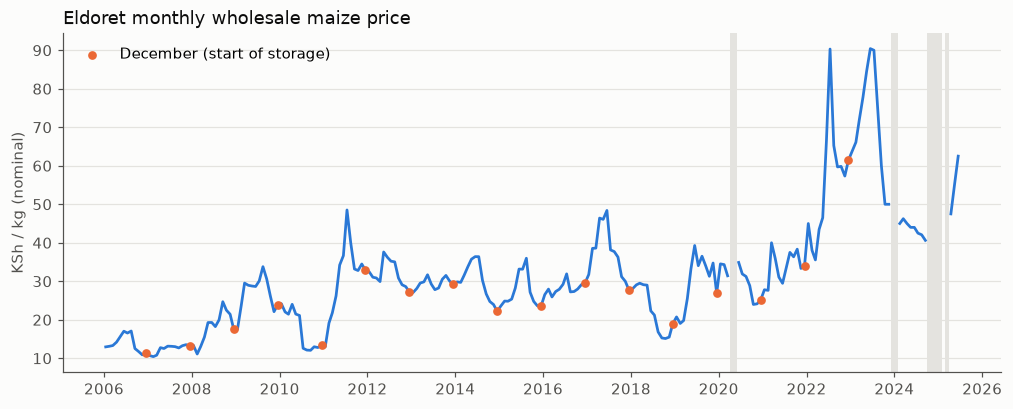

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
t = price.index.to_timestamp() + pd.Timedelta(days=14)
for m in price[price.isna()].index:                  # grey = no price that month
    d = m.to_timestamp() + pd.Timedelta(days=14)
    ax.axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15), color=GRID, lw=0, zorder=0)
ax.plot(t, price.values, color=BLUE, lw=1.8)
# harvest-window lows: mark each December
dec = price[(price.index.month == 12)].dropna()
ax.scatter(dec.index.to_timestamp() + pd.Timedelta(days=14), dec.values, s=22, color=ORANGE,
           zorder=3, label="December (start of storage)")
ax.set_ylabel("KSh / kg (nominal)")
ax.set_title("Eldoret monthly wholesale maize price", loc="left", color=INK)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
plt.show()

**What to note.** Prices trend upward (≈ 13 → 35 KSh/kg over 2006–2021, roughly Kenyan
inflation), swing within every year, and spike in 2022–23 (≈ 90 KSh/kg in July 2022 and June
2023, confirmed by KAMIS). Everything below uses the **full series, 2006-01 → 2025-06**; the
2022–23 seasons are 2 of 17, and Step 8 shows season by season how much they matter.

We work with **monthly log returns** $r_t = \log(P_t / P_{t-1})$ — the natural variable for
multiplicative changes (a 10% rise then a 10% fall do not cancel, but their logs nearly do, and
log changes add over time). A return is defined only when **both** consecutive months have a
price; a change across a missing month is dropped rather than counted as a one-month move.

In [4]:
r = np.log(price).diff().dropna()                    # NaN wherever either month is missing
r.name = "log_return"
full = pd.period_range(r.index.min(), r.index.max(), freq="M")
print(f"{len(r)} monthly returns, {r.index.min()} -> {r.index.max()}")

220 monthly returns, 2006-02 -> 2025-06


## Step 2 — Is there a seasonal cycle?

If prices did not rise predictably after harvest, there would be no reason to store. Each
season is followed from December to November and measured relative to its own
December–January (harvest) price level. Four statistical tests (code in `figures/seasonality.py`):

* **Do the 12 calendar months have different mean returns?** Kruskal–Wallis (a rank-based test
  that does not assume normality) and one-way ANOVA.
* **Is there a consistent annual cycle?** Fit one sine wave (period 12 months) to the returns
  and measure its amplitude. To get a p-value, compare it with 5,000 reshuffled versions of the
  data in which each year's 12 returns are rotated by a random number of months — this keeps
  each year's data intact but destroys any timing shared across years.
* **Does the price go up from harvest more often than chance?** A sign test on whether the
  May–July price was above the December–January price.

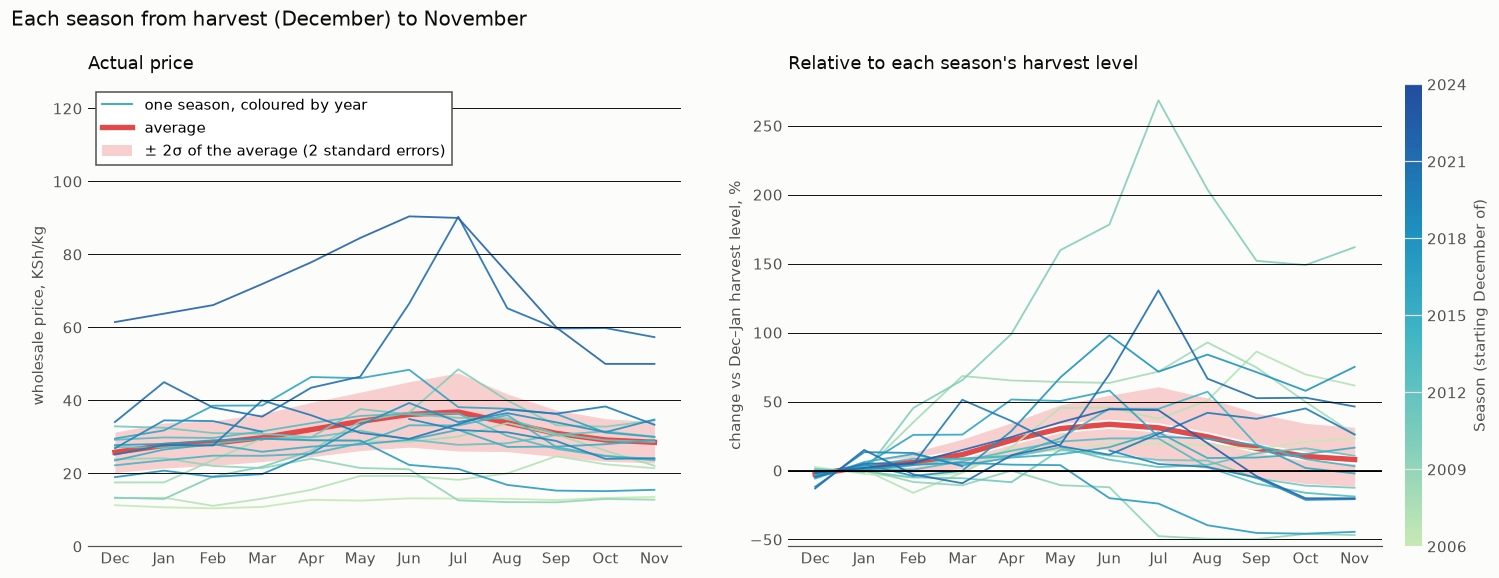

Kruskal-Wallis p                 0.000023
ANOVA p                          0.000081
annual cycle, %/month            6.674546
permutation p                      0.0002
seasons up Dec-Jan -> May-Jul       15/17
sign test p                      0.001175
dtype: object

In [5]:
res = season.run_tests(price, np.random.default_rng(2026))
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5.6))

# right: % relative to each season's Dec-Jan harvest level (lines coloured by year, average, band)
top, bottom = season.panel(axR, "Uasin-Gishu", price, res)
axR.set_ylim(25 * np.floor(bottom / 25) - 5, 25 * np.ceil(top / 25) + 5)
axR.set_ylabel("change vs Dec–Jan harvest level, %")
axR.set_title("Relative to each season's harvest level", loc="left", color=INK, pad=10)
axR.grid(axis="x", visible=False)
# no legend on the right panel: same lines and band as the left panel's legend

# left: actual price for the same seasons, Dec -> Nov
seasons_used = season.season_paths(price).index            # same seasons as the right panel
for yr in seasons_used:
    months = [pd.Period(f"{yr-1}-12", "M")] + [pd.Period(f"{yr}-{m:02d}", "M") for m in range(1, 12)]
    axL.plot(range(12), price.reindex(months).values, color=season.SEASON_CMAP(season.SEASON_NORM(yr - 1)),
             lw=1.2, alpha=.9, zorder=2.2)
# average actual price by month, with ± 2 standard errors of that average (same band as the right panel)
raw = pd.DataFrame({yr: price.reindex([pd.Period(f"{yr-1}-12", "M")] +
                                      [pd.Period(f"{yr}-{m:02d}", "M") for m in range(1, 12)]).values
                    for yr in seasons_used}).T                      # seasons x months
avg_raw, se_raw = raw.mean(), raw.std() / np.sqrt(raw.count())
axL.fill_between(range(12), avg_raw - 2 * se_raw, avg_raw + 2 * se_raw,
                 color=season.AVG_BAND, lw=0, zorder=1.0)
axL.plot(range(12), avg_raw.values, color=season.AVG, lw=3.5, zorder=1.1)
axL.legend(handles=[Line2D([], [], color=season.SEASON_CMAP(0.55), lw=1.2, label="one season, coloured by year"),
                    Line2D([], [], color=season.AVG, lw=3.5, label="average"),
                    Patch(facecolor=season.AVG_BAND, label="± 2σ of the average (2 standard errors)")],
           loc="upper left", **season.LEGEND_BOX)
axL.set_xticks(range(12), ["Dec"] + MONTHS[:11])
axL.set_ylabel("wholesale price, KSh/kg")
axL.set_ylim(0, float(np.nanmax(raw.values)) * 1.4)   # headroom for legend
axL.set_title("Actual price", loc="left", color=INK, pad=10)
axL.set_axisbelow(False)
axL.grid(axis="y", color="black", lw=.6); axL.grid(axis="x", visible=False)
for sp in ("top", "right", "left"):
    axL.spines[sp].set_visible(False)
axL.tick_params(length=0)

fig.suptitle("Each season from harvest (December) to November", x=0.01, ha="left", color=INK, fontsize=13)
fig.subplots_adjust(left=0.06, right=0.9, top=0.86, wspace=0.18)
pos = axR.get_position()
season.season_colorbar(fig, fig.add_axes([0.915, pos.y0, 0.011, pos.height]))
plt.show()

pd.Series({"Kruskal-Wallis p": res["kw_p"], "ANOVA p": res["anova_p"],
           "annual cycle, %/month": 100 * res["amp"], "permutation p": res["amp_p"],
           "seasons up Dec-Jan -> May-Jul": f"{res['pos']}/{len(res['rises'])}",
           "sign test p": res["sign_p"]})

**Average price change by calendar month.** The mean log return into each month, with its
standard error (standard deviation ÷ √(number of years)). These averages are plotted, together
with the smooth seasonal curve fitted to them, in Step 3.

In [6]:
rows = []
for m in range(1, 13):
    x = r[r.index.month == m].values
    mean, se = qk.mc_estimate(x)
    rows.append({"month": MONTHS[m - 1], "n": len(x), "mean": mean, "se": se})
mm = pd.DataFrame(rows).set_index("month")
mm.loc[["Dec"] + MONTHS[:11]].round(4)        # displayed in season order, Dec -> Nov

,n,mean,se
month,,,
Dec,17,-0.0157,0.0256
Jan,17,0.0572,0.0220
Feb,18,0.0273,0.0340
Mar,19,0.0494,0.0253
Apr,18,0.0762,0.0236
May,19,0.0684,0.0269
Jun,19,0.0393,0.0282
Jul,19,-0.0207,0.0402
Aug,19,-0.0446,0.0297


**Reading.** Prices fall from August to December (the new harvest arriving) and rise from
January to June (stocks running down). Every test rejects "no seasonal cycle", and the price was
higher in May–July than at the harvest level in 15 of 17 seasons. So storage has a reason to
exist; the question for Steps 6–8 is whether this rise beats interest, fees and losses once the
bad years (the two seasons where prices fell) are included.

## Step 3 — The seasonal growth curve

Twelve separate monthly averages are noisy (each rests on only 17–19 years). We smooth them by
fitting a short Fourier series in the calendar month,

$$ g(m) = a_0 + \sum_{k=1}^{K} \Big[ a_k \sin\tfrac{2\pi k m}{12} + b_k \cos\tfrac{2\pi k m}{12} \Big], $$

where $g(m)$ is the expected log return **into** month $m$, by least squares
(`scipy.optimize.least_squares`). The number of harmonics $K$ is chosen by **leave-one-year-out
cross-validation**: hold out one year, fit on the others, measure the squared error on the
held-out year, and repeat for every year. The model with the smallest out-of-sample error wins.

In [7]:
def design(months, K):
    cols = [np.ones(len(months))]
    for k in range(1, K + 1):
        cols += [np.sin(2 * np.pi * k * months / 12), np.cos(2 * np.pi * k * months / 12)]
    return np.column_stack(cols)

def fit_drift(r, K):
    X, y = design(r.index.month.values, K), r.values
    res = least_squares(lambda beta: X @ beta - y, x0=np.zeros(X.shape[1]))
    return res.x

def g_of(beta, K, months=np.arange(1, 13)):
    return design(months, K) @ beta

def cv_score(r, K):
    err = []
    for yr in sorted(set(r.index.year)):
        tr, te = r[r.index.year != yr], r[r.index.year == yr]
        if K == "12 means":
            pred = tr.groupby(tr.index.month).mean().reindex(te.index.month).values
        else:
            pred = g_of(fit_drift(tr, K), K, te.index.month.values)
        err.append((te.values - pred) ** 2)
    return np.concatenate(err).mean()

cv = pd.Series({(f"K={K}" if K != "12 means" else K): cv_score(r, K) for K in [0, 1, 2, 3, "12 means"]})
(cv / cv["K=0"]).round(4).rename("CV MSE relative to constant drift")

K=0         1.0000
K=1         0.8754
K=2         0.8911
K=3         0.8998
12 means    0.9287
Name: CV MSE relative to constant drift, dtype: float64

chosen K = 1


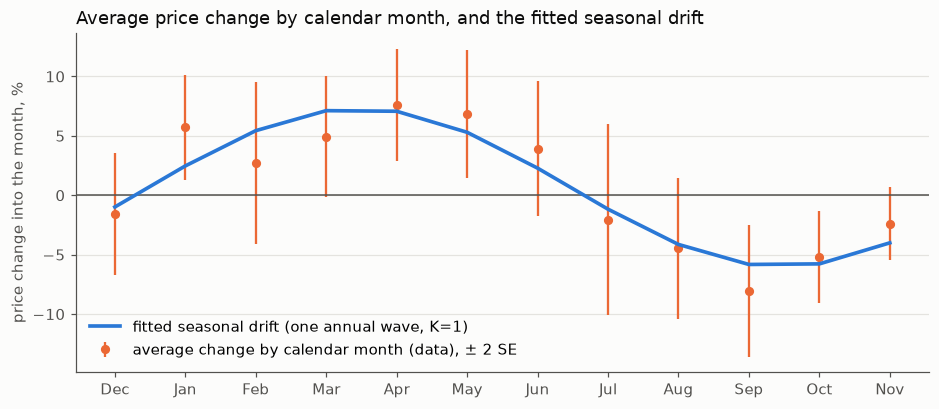

Dec     0.0
Jan     2.5
Feb     8.2
Mar    16.2
Apr    24.7
May    31.5
Jun    34.5
Jul    33.0
Aug    27.6
Name: expected price vs December, %, dtype: float64

In [8]:
K = int(cv.drop("12 means").idxmin().split("=")[1])
print("chosen K =", K)
g = pd.Series(g_of(fit_drift(r, K), K), index=MONTHS)

SEASON_ORDER = ["Dec"] + MONTHS[:11]          # plot in season order: harvest (Dec) -> Nov
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(np.arange(12), 100 * mm.loc[SEASON_ORDER, "mean"], yerr=200 * mm.loc[SEASON_ORDER, "se"],
            fmt="o", ms=5, color=ORANGE, capsize=0, lw=1.5,
            label="average change by calendar month (data), ± 2 SE", zorder=2)
ax.plot(range(12), 100 * g[SEASON_ORDER].values, color=BLUE, lw=2.4,
        label=f"fitted seasonal drift (one annual wave, K={K})", zorder=3)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(range(12), SEASON_ORDER); ax.set_ylabel("price change into the month, %")
ax.set_title("Average price change by calendar month, and the fitted seasonal drift", loc="left", color=INK)
ax.legend(frameon=False, loc="lower left"); ax.grid(axis="x", visible=False)
plt.show()

# implied average seasonal path from December (the storage start), as % above December
path = 100 * (np.exp(np.cumsum(np.r_[0, g[MONTHS[:8]].values])) - 1)
pd.Series(path, index=["Dec"] + MONTHS[:8]).round(1).rename("expected price vs December, %")

## Step 4 — The random part of price changes, and checking the model

### 4a. Returns with and without the seasonal curve

The model used from Step 6 on is **geometric Brownian motion (GBM)**: the log price performs a
random walk with drift. Each month the log price moves by the seasonal amount $g(m)$ plus an
independent normal shock. The shocks are the residuals $\varepsilon_t = r_t - g(m_t)$; their
standard deviation, scaled to a year, is the volatility $\sigma$.

The table checks the model's assumptions on raw returns $r_t$ and on the residuals $\varepsilon$:
are the shocks normal (Shapiro–Wilk test), are they uncorrelated over time (Ljung–Box test on
the first 12 autocorrelations), and is their *size* uncorrelated over time (Ljung–Box on
$|\varepsilon|$, which detects "volatility clustering": calm and turbulent stretches)? On raw
returns, Ljung–Box partly detects the seasonal cycle itself, so the residual column is the
relevant test.

In [9]:
eps = r - g.values[r.index.month - 1]
sigma = qk.annualized_vol(eps, periods_per_year=12)

def gbm_checks(x):
    nt = qk.test_normality(x)
    return {"n": len(x), "volatility (annualized)": qk.annualized_vol(x, 12),
            "skew": nt["skewness"], "excess kurtosis": nt["excess_kurtosis"],
            "normality p (Shapiro)": nt["p_shapiro"],
            "Ljung-Box, 12 lags p": qk.ljung_box(x.values, 12)["lb_pvalue"][-1],
            "Ljung-Box on |x|, 12 lags p": qk.ljung_box(np.abs(x.values), 12)["lb_pvalue"][-1]}

display(pd.DataFrame({"raw returns r": gbm_checks(r), "de-seasonalized ε": gbm_checks(eps)}).round(4))

# autocorrelation of ε by lag on the calendar-aligned series (gaps stay NaN, so pairs are only
# formed between months that are exactly L apart)
eps_cal = eps.reindex(full)
acf = pd.Series({L: eps_cal.corr(eps_cal.shift(L)) for L in range(1, 13)})
print(f"autocorrelation of ε by lag (approx. 95% noise band ±{2 / np.sqrt(len(eps)):.2f}):")
acf.round(2).to_frame("acf").T

,raw returns r,de-seasonalized ε
n,220.0000,220.0000
volatility (annualized),0.4338,0.4014
skew,-0.0208,-0.0595
excess kurtosis,1.7887,1.8288
normality p (Shapiro),0.0000,0.0002
"Ljung-Box, 12 lags p",0.0039,0.0015
"Ljung-Box on |x|, 12 lags p",0.4642,0.0104


autocorrelation of ε by lag (approx. 95% noise band ±0.13):


,1,2,3,4,5,6,7,8,9,10,11,12
acf,0.05,-0.03,-0.08,-0.04,0.18,0.14,-0.12,-0.08,-0.03,0.02,-0.05,-0.21


**Reading.** Removing the seasonal curve lowers the volatility from ≈ 0.43 to ≈ 0.40: part of
the raw month-to-month variation was the predictable cycle. The remaining shocks are **not**
independent normal variables:

* **fat tails** (excess kurtosis ≈ 2; normality rejected): large monthly moves are more common
  than a normal distribution allows;
* **no month-to-month persistence** (lag-1 autocorrelation ≈ 0.05), but a **negative
  correlation at lag 12** (≈ −0.2, outside the noise band) — this is what makes Ljung–Box
  reject. A month that was unusually strong one year tends to be weak in the same month the
  next year (e.g. a shortage year followed by a recovery harvest). Two consequences: the
  seasonal curve varies from year to year around the average estimated here, and in Step 5 the
  forecast "repeat last year's change" should do *badly*;
* **volatility clustering** (Ljung–Box on |ε| rejects).

These are the ways the model can be wrong. The Step 8 replay on real price paths does not use
the model's random shocks, so it is the check against them. Note also that under this model σ
does **not** change *when* to sell (Step 6 shows the answer is a fixed month); it only enters
the value through the σ²/2 term explained in 4c.

### 4b. Volatility over time

Volatility over the **past 12 calendar months**: the standard deviation of the monthly returns
observed in that year × √12, computed only when at least 9 of the 12 returns exist. Months with
no price are shaded grey; points whose 12-month window contains a gap are drawn dotted. Both
the raw and the de-seasonalized returns are shown; dashed lines are the full-sample values.

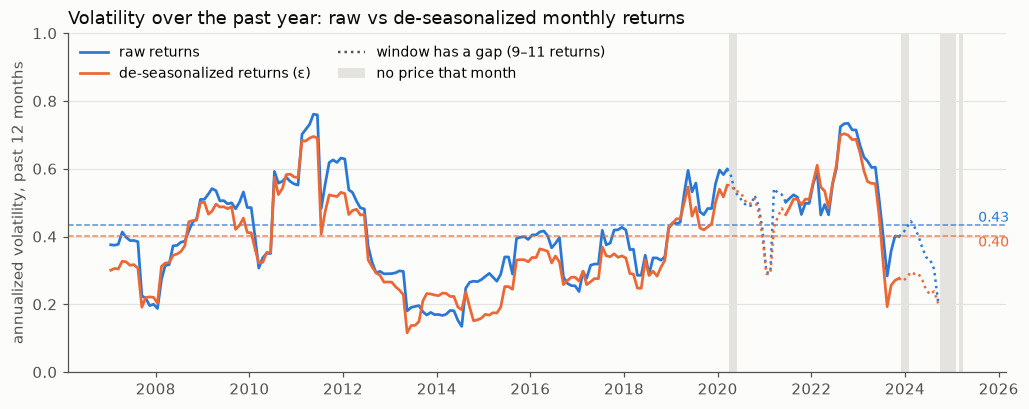

windows with a gap (9–11 returns): 24, in years [2020, 2021, 2023, 2024]
windows not computed (< 9 returns): 9: 2024-10 -> 2025-06
median: raw 0.405, de-seasonalized 0.343; max 0.76 (2011-05), min 0.13 (2014-07)
years with the highest de-seasonalized volatility: {2022: 0.7, 2011: 0.7, 2023: 0.65, 2010: 0.58, 2020: 0.55}


,n,vol
month,,
"Mar–Apr, Sep–Oct",74,0.358
harvest Nov–Feb,70,0.366
lean May–Aug,76,0.470


In [10]:
MIN_RET = 9
def vol_past_year(x):
    xc = x.reindex(full)
    vol = xc.rolling(12, min_periods=MIN_RET).std() * np.sqrt(12)
    n = xc.rolling(12, min_periods=1).count()
    vol.iloc[:11] = np.nan                  # first 11 months: less than a year of history, not a gap
    n.iloc[:11] = np.nan
    return vol, n

rv, n_ret = vol_past_year(r)
rv_eps, _ = vol_past_year(eps)
t = full.to_timestamp() + pd.Timedelta(days=14)

fig, ax = plt.subplots(figsize=(11, 4))
for m in price[price.isna()].index:                                  # grey = no price that month
    d = m.to_timestamp() + pd.Timedelta(days=14)
    ax.axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15), color=GRID, lw=0, zorder=0)
complete = (n_ret == 12).values
handles = []
for series, level, col, lab, va in [(rv, qk.annualized_vol(r, 12), BLUE, "raw returns", "bottom"),
                                    (rv_eps, sigma, ORANGE, "de-seasonalized returns (ε)", "top")]:
    v = series.values
    solid = np.where(complete, v, np.nan)
    # dotted where the window has a gap; extend one point so solid and dotted segments join
    gap = complete == False
    gap_ext = gap | np.r_[gap[1:], False] | np.r_[False, gap[:-1]]
    dotted = np.where(gap_ext, v, np.nan)
    handles.append(ax.plot(t, solid, color=col, lw=1.8, label=lab)[0])
    ax.plot(t, dotted, color=col, lw=1.6, ls=":")
    ax.axhline(level, color=col, lw=1, ls="--", alpha=.8)
    ax.text(t[-1] + pd.Timedelta(days=40), level, f"{level:.2f}", color=col, va=va, fontsize=9)
handles += [Line2D([], [], color=INK2, lw=1.6, ls=":", label=f"window has a gap ({MIN_RET}–11 returns)"),
            Patch(facecolor=GRID, label="no price that month")]
ax.set_ylabel("annualized volatility, past 12 months")
ax.set_title("Volatility over the past year: raw vs de-seasonalized monthly returns", loc="left", color=INK)
ax.set_ylim(0, 1.0)                                                   # headroom for the legend
ax.legend(handles=handles, frameon=False, loc="upper left", ncol=2, fontsize=9)
ax.grid(axis="x", visible=False)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

gap_years = sorted({p.year for p in full[(n_ret.values < 12) & (n_ret.values >= MIN_RET)]})
too_few = full[(n_ret.values < MIN_RET) & (np.arange(len(full)) >= 11)]
print(f"windows with a gap ({MIN_RET}–11 returns): {int(((n_ret < 12) & (n_ret >= MIN_RET)).sum())}, in years {gap_years}")
print(f"windows not computed (< {MIN_RET} returns): {len(too_few)}: {too_few.min()} -> {too_few.max()}" if len(too_few) else "none")
print(f"median: raw {rv.median():.3f}, de-seasonalized {rv_eps.median():.3f}; "
      f"max {rv.max():.2f} ({rv.idxmax()}), min {rv.min():.2f} ({rv.idxmin()})")
top_years = rv_eps.groupby(rv_eps.index.year).max().sort_values(ascending=False)
print("years with the highest de-seasonalized volatility:", {int(y): round(v, 2) for y, v in top_years.head(5).items()})

# volatility by season (de-seasonalized): harvest/early storage (Nov-Feb), lean (May-Aug), other
season_of = lambda m: "harvest Nov–Feb" if m in (11, 12, 1, 2) else ("lean May–Aug" if m in (5, 6, 7, 8) else "Mar–Apr, Sep–Oct")
eps.groupby(eps.index.month.map(season_of)).agg(n="count", vol=lambda x: x.std() * np.sqrt(12)).round(3)

**Reading.** The random part of the price is large (σ ≈ 0.40 per √year; for comparison a broad
stock-market index is typically 0.15–0.20) and not constant: calm and turbulent periods
alternate (peak years printed above). Both lines pick out the same periods; the de-seasonalized
one is usually lower because part of the raw variation is the predictable cycle. By season, the
shocks are largest in May–August (≈ 0.47) — exactly when grain that is still stored is exposed
— and similar in the rest of the year (≈ 0.36–0.37). The 2024–25 gaps leave too few months for
a one-year estimate at the end of the series, so the line stops.

### 4c. From the typical path to the expected path (the σ²/2 term)

$g(m)$ is the expected **log** return, which describes the *typical* (median) price path. The
storage decision needs the *expected* (mean) price, which is higher: for a normal variable $X$,
$\mathbb{E}[e^{X}] = e^{\mathbb{E}[X] + \operatorname{Var}[X]/2}$ (Jensen's inequality for the
lognormal distribution). So the expected growth rate of the price itself is

$$ \mu(m) = 12\,g(m) + \tfrac{1}{2}\sigma^2 \quad \text{(per year)} . $$

With σ ≈ 0.4 the correction is ≈ 8% per year. `qk.gbm_paths` and `qk.binomial_optimal_stopping`
take $\mu$ as their growth-rate input.

### 4d. Does the model reproduce history? (simulation check)

For every historical month $t$ with prices at $t$ and $t+h$ ($h$ = 3 and 6 months), simulate
20,000 paths of the model starting in the same calendar month and ask whether the actual log
change falls between the simulated 5th and 95th percentiles. If the model describes the data
well, this should happen about 90% of the time.

In [11]:
mu = 12 * g + 0.5 * sigma ** 2            # arithmetic drift into each calendar month, annualized

def simulate_log_change(start_month, h, n_sims=20_000, k=4):
    # start_month: 0-based index = calendar month mod 12, so step i ends in MONTHS[(start_month + i) % 12]
    mu_path = np.repeat(mu.values[[(start_month + i) % 12 for i in range(h)]], k)
    S = qk.gbm_paths(1.0, sigma, h / 12, 0.0, h * k, n_sims, mu=mu_path, rng=rng)
    return np.log(S[:, -1])

lp = np.log(price)
coverage = []
for h in (3, 6):
    bands = {m0: np.quantile(simulate_log_change(m0, h), [.05, .95]) for m0 in range(12)}
    realized = (lp.shift(-h) - lp).dropna()
    inside = [bands[p.month % 12][0] <= x <= bands[p.month % 12][1] for p, x in realized.items()]
    coverage.append({"horizon (months)": h, "n windows": len(inside),
                     "share inside 5–95% band": np.mean(inside)})
pd.DataFrame(coverage).set_index("horizon (months)").round(3)

,n windows,share inside 5–95% band
horizon (months),,
3,215,0.893
6,212,0.896


Indexing convention: a step that ends in calendar month $m$ uses $\mu(m)$, matching how
$g(m)$ was fitted (the return *into* month $m$).

### 4e. Save the fitted model for Steps 5–9

In [12]:
params = {"window": [str(price.index.min()), str(price.index.max())], "K": K, "sigma": sigma,
          "g_log_monthly": g.to_dict(), "mu_arith_annual": mu.to_dict()}
Path("data/processed/model_params.json").write_text(json.dumps(params, indent=2))
mu.round(3).rename("mu(m), annualized")

Jan    0.376
Feb    0.733
Mar    0.935
Apr    0.929
May    0.716
Jun    0.354
Jul   -0.060
Aug   -0.416
Sep   -0.618
Oct   -0.612
Nov   -0.400
Dec   -0.038
Name: mu(m), annualized, dtype: float64

## Summary of Steps 1–4

* **Data:** 225 of 234 months of Eldoret wholesale prices, 2006-01 → 2025-06, nominal KSh/kg.
* **Seasonal cycle:** strong and stable — prices fall August → December and rise January → June;
  up from harvest to May–July in 15 of 17 seasons; significant in every test.
* **Model:** log price = random walk with a seasonal drift $g(m)$ (one annual sine wave, chosen
  by cross-validation) and volatility σ ≈ 0.40; expected growth rate $\mu(m) = 12g(m) + \sigma^2/2$.
  Saved to `data/processed/model_params.json`.
* **Model checks:** the random shocks have fat tails, a year-to-year reversal (lag-12
  correlation ≈ −0.2) and volatility clustering, so the model is an approximation; still,
  actual 3- and 6-month price changes fall inside its 90% band ≈ 89–90% of the time.

## Step 5 — Does the seasonal curve predict prices it has not seen?

The storage decision relies on $g(m)$, so check that it **predicts out of sample**. For every
month $t$ from 2011-01 on (so there are at least 5 years of history), re-fit $g$ using only data
up to $t$ and forecast 1 and 3 months ahead: $\hat P_{t+h} = P_t \exp\big(\sum_{i=1}^{h} g(m_{t+i})\big)$.
Compared with three simple alternatives:

* **last price** (no change): $\hat P_{t+h} = P_t$ — a random walk without drift;
* **12 monthly averages** (the unsmoothed version of $g$, also re-estimated at each $t$);
* **repeat last year's change**: $\hat P_{t+h} = P_t \cdot P_{t+h-12} / P_{t-12}$.

Scored by mean absolute error (MAE) and root-mean-square error (RMSE) in KSh/kg — the Zindi
challenge's metrics — and by the mean absolute **log** error (%), which is not dominated by the
high-price years. To test whether the model beats "last price", the forecast-error differences
are resampled by whole years (a bootstrap; errors within a year are correlated) to get a 95%
confidence interval.

In [13]:
rows = []
for t in price.index:
    if t < pd.Period("2011-01", "M") or np.isnan(price[t]):
        continue
    hist = r[r.index <= t]
    beta_t = fit_drift(hist, K)                     # Step 3 fit, using data up to t only
    clim = hist.groupby(hist.index.month).mean()
    for h in (1, 3):
        T = t + h
        if T not in price.index or np.isnan(price[T]):
            continue
        months = np.array([(t + i).month for i in range(1, h + 1)])
        a, b = t - 12, T - 12
        ly = (price[t] * price[b] / price[a]
              if a in price.index and b in price.index and np.isfinite(price[a]) and np.isfinite(price[b]) else np.nan)
        rows.append({"origin": t, "h": h, "actual": price[T],
                     "seasonal drift (model)": price[t] * np.exp((design(months, K) @ beta_t).sum()),
                     "12 monthly means": price[t] * np.exp(clim.reindex(months).sum()),
                     "last price": price[t], "last year's change": ly})
fc = pd.DataFrame(rows)
METHODS = ["seasonal drift (model)", "12 monthly means", "last price", "last year's change"]

score = []
for h, d in fc.groupby("h"):
    d = d.dropna()
    for mth in METHODS:
        e, le = d[mth] - d.actual, np.log(d[mth] / d.actual)
        score.append({"h (months)": h, "method": mth, "n": len(d), "MAE (KSh/kg)": abs(e).mean(),
                      "RMSE (KSh/kg)": np.sqrt((e ** 2).mean()), "MAE of log error, %": 100 * abs(le).mean()})
pd.DataFrame(score).set_index(["h (months)", "method"]).round(2)

n  MAE (KSh/kg)  RMSE (KSh/kg)  \
h (months) method                                                     
1          seasonal drift (model)  157          3.07           4.80   
           12 monthly means        157          3.14           5.00   
           last price              157          3.34           5.30   
           last year's change      157          5.12           7.89   
3          seasonal drift (model)  151          5.42           8.12   
           12 monthly means        151          5.54           8.19   
           last price              151          6.82           9.96   
           last year's change      151          9.52          14.31   

                                   MAE of log error, %  
h (months) method                                       
1          seasonal drift (model)                 8.39  
           12 monthly means                       8.58  
           last price                             8.94  
           last year's change                    13.38  
3          seasonal drift (model)                15.12  
           12 monthly means                      15.51  
           last price                            18.56  
           last year's change                    24.85

In [14]:
boot = []
brng = np.random.default_rng(2026)
for h, d in fc.groupby("h"):
    d = d.dropna()
    gain = abs(np.log(d["last price"] / d.actual)) - abs(np.log(d["seasonal drift (model)"] / d.actual))
    years = d.origin.map(lambda p: p.year).values
    uy = np.unique(years)
    by_year = {y: gain[years == y].values for y in uy}
    reps = [np.concatenate([by_year[y] for y in brng.choice(uy, len(uy))]).mean() for _ in range(5000)]
    boot.append({"h (months)": h, "model wins (share of months)": (gain > 0).mean(),
                 "mean gain in |log error|, % points": 100 * gain.mean(),
                 "95% CI low": 100 * np.quantile(reps, .025), "95% CI high": 100 * np.quantile(reps, .975)})
pd.DataFrame(boot).set_index("h (months)").round(2)

,model wins (share of months),"mean gain in |log error|, % points",95% CI low,95% CI high
h (months),,,,
1,0.59,0.55,-0.21,1.31
3,0.64,3.44,0.58,6.15


**Reading.** Three months ahead — the horizon that matters for storage — the seasonal curve
clearly beats "last price", and the confidence interval excludes zero; one month ahead the gain
is small and not significant (one month of seasonal drift is small compared with one month of
noise). The smooth curve also beats the 12 raw monthly averages, confirming the
cross-validation in Step 3. "Repeat last year's change" is the worst forecast at both horizons,
as the lag-12 correlation in Step 4 predicted: last year's surprise tends to reverse, not repeat.

## Step 6 — When to sell: solving the stopping problem

**The problem.** A farmer holds 1 kg of maize in **December** worth $P_0$ and may sell at the end
of any month $t = 1, \dots, 11$. Selling at month $t$ earns the price $P_t$, which is worth
$P_t\, e^{-(i + c)\,t/12}$ in December terms (interest and holding costs, as in the introduction). The
farmer wants the selling rule — which may depend on the price seen so far — that maximizes the
expected value. This is an **optimal stopping problem**; in finance it is called valuing an
*American-style option* (a right, but not an obligation, to act at any time before a deadline).

**The method: a binomial tree and dynamic programming.** Time is split into steps of length
$\Delta$ years (8 steps per month, $\Delta = 1/96$). In each step the price moves up by a factor
$u = e^{\sigma\sqrt{\Delta}}$ or down by $d = 1/u$ — a discrete random walk in log price that
converges to the GBM model as $\Delta \to 0$. The up-probability $p$ is set each step so that the
expected growth matches the seasonal rate: $p\,u + (1-p)\,d = e^{\mu(m)\Delta}$. The possible
prices form a recombining lattice, called a **binomial tree**. Working **backwards** from
November, the value at every node, where the price is $P$, is

$$ V = \max\Big(\underbrace{P}_{\text{sell now}},\; \underbrace{e^{-(i+c)\Delta}\,\big[p\,V_{\text{up}} + (1-p)\,V_{\text{down}}\big]}_{\text{wait one step}}\Big), $$

the Bellman equation of the stopping problem. The value at the first node is what the stored
grain is worth in December under the optimal rule. `qk.binomial_optimal_stopping` implements
this.

**Inputs** (see Notation and inputs):

| | Warehouse (agriGHALA-type) | On-farm |
|---|---|---|
| Interest rate $i$ | 15%/yr | 15%/yr |
| Storage fee | 3%/yr + 1.5% once | 0 |
| Losses | 0 | 20%/yr |

**Check first:** with the payoff $\max(100 - P, 0)$ instead of $P$ (and $P_0 = 100$, σ = 0.3,
$i$ = 5%, one year, no seasonal drift), this is a standard textbook problem with a known solution
(`qk.american_put`); the two must agree.

In [15]:
print("binomial_optimal_stopping with put payoff:",
      qk.binomial_optimal_stopping(100, .3, 1, 500, lambda S: np.maximum(100 - S, 0), .05))
print("qk.american_put (textbook solution):       ", qk.american_put(100, 100, .3, 1, .05, n_steps=500))

binomial_optimal_stopping with put payoff: 9.867327360098583
qk.american_put (textbook solution):        9.867327360098583


In [16]:
R_LOAN = 0.15
SCENARIOS = {"warehouse": dict(fee=0.03, loss=0.00, once=0.015),
             "on-farm (20% loss)": dict(fee=0.00, loss=0.20, once=0.0)}
SELL_MONTHS = MONTHS[:11]                 # steps Dec->Jan, ..., Oct->Nov: sale possible at end of Jan..Nov
H = len(SELL_MONTHS)

def store_value(fee, loss, k=8, r_=R_LOAN, sigma_=sigma, H_=H):
    drift = np.repeat(mu[SELL_MONTHS[:H_]].values, k)
    return qk.binomial_optimal_stopping(1.0, sigma_, H_ / 12, H_ * k, lambda S: S, r_, drift=drift,
                                        holding_cost=fee + loss, return_exercise=True)

S_ILLUS = 40.0                            # illustrative December price, KSh/kg (≈ 3,600 per 90-kg bag)
rows = []
for name, c in SCENARIOS.items():
    v, ex = store_value(c["fee"], c["loss"])
    net = v - 1 - c["once"]
    rows.append({"scenario": name, "value per KSh of Dec price": v,
                 "gain from storing, % of Dec price": 100 * net,
                 f"gain, KSh per 90-kg bag at {S_ILLUS:.0f} KSh/kg": 90 * S_ILLUS * net})
w1, w32 = store_value(0.03, 0.0, k=1)[0], store_value(0.03, 0.0, k=32)[0]
print(f"convergence (warehouse): {w1:.6f} with 1 step per month, {w32:.6f} with 32")
pd.DataFrame(rows).set_index("scenario").round(3)

convergence (warehouse): 1.280103 with 1 step per month, 1.280103 with 32


,value per KSh of Dec price,"gain from storing, % of Dec price","gain, KSh per 90-kg bag at 40 KSh/kg"
scenario,,,
warehouse,1.280,26.510,954.369
on-farm (20% loss),1.176,17.579,632.844


**Where and when does the tree sell?** The figure shows the tree for the warehouse case
with one step per month (drawn by `figures/storage_tree.py`; its value matches
`qk.binomial_optimal_stopping` exactly). Blue: waiting is worth more than selling; red: selling
is optimal; grey: never reached because the grain has already been sold. Node size is the
probability of reaching the node.

![Storage decision on the binomial tree](figures/storage_tree.png)

Compare the tree with the simplest possible rule — decide in December to sell in one fixed
month $t$, whatever happens. Its expected value per KSh of December price is

$$ \text{fixed}(t) = \exp\Big(\sum_{s=1}^{t} \frac{\mu(m_s)}{12} - (i + c)\,\frac{t}{12}\Big). $$

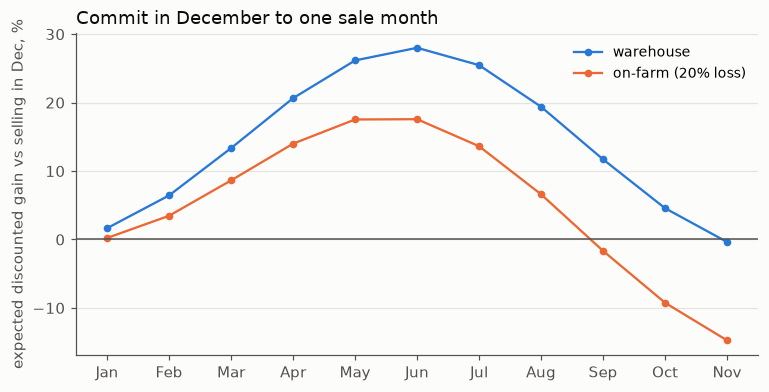

,tree value,best fixed month,fixed-month value,tree − best fixed month
scenario,,,,
warehouse,1.28010,Jun,1.28010,0.0
on-farm (20% loss),1.17579,Jun,1.17579,0.0


In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
summary = []
for (name, c), col in zip(SCENARIOS.items(), [BLUE, ORANGE]):
    v = store_value(c["fee"], c["loss"])[0]
    tm = np.arange(1, H + 1) / 12
    fixed = np.exp(np.cumsum(mu[SELL_MONTHS].values / 12) - (R_LOAN + c["fee"] + c["loss"]) * tm)
    ax.plot(range(1, H + 1), 100 * (fixed - 1), "o-", color=col, ms=4, label=name)
    best = int(np.argmax(fixed))
    summary.append({"scenario": name, "tree value": v, "best fixed month": SELL_MONTHS[best],
                    "fixed-month value": fixed[best], "tree − best fixed month": v - fixed[best]})
ax.set_xticks(range(1, H + 1), SELL_MONTHS)
ax.axhline(0, color=INK2, lw=1)
ax.set_ylabel("expected discounted gain vs selling in Dec, %")
ax.set_title("Commit in December to one sale month", loc="left", color=INK)
ax.grid(axis="x", visible=False); ax.legend(frameon=False, fontsize=9)
plt.show()
pd.DataFrame(summary).set_index("scenario").round(5)

**Reading — and an important property of this model.**

* Storing pays in both cases: ≈ +27% of the December price in a warehouse (after the one-off
  fee) and ≈ +18% on-farm at 20%/yr losses. Most of the difference is the loss rate.
* How +34% becomes +27% (warehouse, sale at the end of June, $t = 6$ months = 0.5 yr): the
  *typical* (median) price rises ≈ +34% (Step 3); the *expected* (mean) price is higher by
  $e^{\sigma^2 \times 0.5/2}$, ≈ +40% (Step 4c); interest plus fees at 18%/yr for half a year
  multiply by $e^{-0.09}$, leaving ≈ +28%; the 1.5% one-off fee leaves ≈ +27%.
* The tree value is the same with 1 or 32 steps per month and equals the **best fixed month**
  exactly: the optimal rule is "hold until the end of June, then sell", and in each month either
  *every* node sells or *none* does (the all-red June column in the figure).

**Why the rule depends only on the calendar.** The payoff is the price $P$, every cost is
proportional to $P$, and in this model the expected future growth does not depend on the current
price. Then the value is linear in the price, $V(P,t) = P\,f(t)$, so "sell now" versus "wait" is
the same comparison at every price — only the date matters. The tree therefore reduces to the
inequality from the introduction, checked month by month: hold while next month's expected rise
($\mu(m)/12$) beats the monthly cost of waiting ($(i+c)/12 \approx 1.5\%$), and sell when it no
longer does — at the end of June. A price-dependent rule ("sell once the price reaches X") cannot
come out of this model; whether the data supports one anyway is tested in Step 8.

## Step 7 — Independent check by simulation (Monte Carlo)

Under this model the optimal rule is "sell at the end of the best month" (Step 6). Simulate
200,000 random price paths from December with the same drift $\mu(m)$ and volatility σ
(`qk.gbm_paths`), sell each path at that month, apply the same interest and holding costs, and
average (`qk.mc_estimate` gives the mean and its standard error). This checks the tree and the
σ²/2 conversion with a completely different calculation.

In [18]:
mc_rows = []
for name, c in SCENARIOS.items():
    cost = R_LOAN + c["fee"] + c["loss"]
    tm = np.arange(1, H + 1) / 12
    fixed = np.exp(np.cumsum(mu[SELL_MONTHS].values / 12) - cost * tm)
    j = int(np.argmax(fixed))                                  # index of the best sale month
    S = qk.gbm_paths(1.0, sigma, H / 12, 0.0, H * 8, 200_000,
                     mu=np.repeat(mu[SELL_MONTHS].values, 8), rng=rng)
    pay = S[:, (j + 1) * 8] * np.exp(-cost * (j + 1) / 12)
    mean, se = qk.mc_estimate(pay)
    tree = store_value(c["fee"], c["loss"])[0]
    mc_rows.append({"scenario": name, "sell in": SELL_MONTHS[j], "Monte Carlo": mean, "SE": se,
                    "tree": tree, "(MC − tree) / SE": (mean - tree) / se})
pd.DataFrame(mc_rows).set_index("scenario").round(4)

,sell in,Monte Carlo,SE,tree,(MC − tree) / SE
scenario,,,,,
warehouse,Jun,1.2806,0.0008,1.2801,0.6152
on-farm (20% loss),Jun,1.1765,0.0008,1.1758,0.8834


The simulated mean agrees with the tree to within one standard error in both cases.

## Step 8 — Replaying the decision on real seasons (the main test)

Does storing actually pay on the **real** Eldoret prices, after interest, fees and losses? For
every season with a December price (starts Dec 2006 → Dec 2022; Dec 2023 and Dec 2024 are
missing), **using only information available at the time** (a "backtest"):

1. re-estimate the seasonal curve and σ with data up to the November before the season;
2. choose the sale month that the model says is best for that season's costs (Step 6);
3. compute the actual gain per KSh of December price, for a sale at month $t$,
   $\;(P_t/P_0)\, e^{-(i+c)\,t/12} - 1 - \text{one-off fee}$,
   compared with **selling at harvest** (gain 0). If the planned month has no price, the grain is
   sold in the next month that has one.

The uncertainty of the average gain is estimated by resampling the seasons with replacement
(a bootstrap, 5,000 resamples).

In [19]:
def model_until(t_end):
    # seasonal log drift and sigma re-estimated with returns up to t_end (Step 3 / 4 methods)
    rr = r[r.index <= t_end]
    g_ = pd.Series(g_of(fit_drift(rr, K), K), index=MONTHS)
    s_ = qk.annualized_vol(rr - g_.values[rr.index.month - 1], 12)
    return g_, 12 * g_ + 0.5 * s_ ** 2

def season_gain(y, c, X=np.inf, r_=R_LOAN):
    # realized gain for the season starting December y-1; X = optional early-sale threshold (below)
    d0 = pd.Period(f"{y-1}-12", "M")
    if d0 not in price.index or np.isnan(price[d0]):
        return np.nan, None
    g_, mu_ = model_until(d0 - 1)
    cost = r_ + c["fee"] + c["loss"]
    tm = np.arange(1, H + 1) / 12
    fixed = np.exp(np.cumsum(mu_[SELL_MONTHS].values / 12) - cost * tm)
    if fixed.max() <= 1:
        return 0.0, "Dec"                                       # model says sell at harvest
    j = int(np.argmax(fixed)) + 1                               # planned sale: end of month j (1 = Jan)
    cg = np.cumsum(g_[SELL_MONTHS].values)                      # typical log path from December
    for i in range(1, H + 1):
        p = price.get(d0 + i, np.nan)
        if np.isnan(p):
            continue
        if i >= j or p / price[d0] >= (1 + X) * np.exp(cg[i - 1]):
            return p / price[d0] * np.exp(-cost * i / 12) - 1 - c["once"], SELL_MONTHS[i - 1]
    return np.nan, None

SC_BT = {k_: SCENARIOS[k_] for k_ in ["warehouse", "on-farm (20% loss)"]}
rows = []
for y in range(2007, 2026):
    rec = {"season (Dec start)": y - 1}
    for name, c in SC_BT.items():
        gain, month = season_gain(y, c)
        rec[f"{name}: sold in"] = month
        rec[f"{name}: gain"] = gain
    rows.append(rec)
bt = pd.DataFrame(rows).set_index("season (Dec start)")
bt.round(3)

,warehouse: sold in,warehouse: gain,on-farm (20% loss): sold in,on-farm (20% loss): gain
season (Dec start),,,,
2006,Jun,0.051,Jun,-0.021
2007,Jun,0.323,Jun,0.229
2008,Jul,0.532,Jul,0.401
2009,Jul,-0.540,Jul,-0.570
2010,Jun,1.495,May,1.215
2011,Jun,-0.008,Jun,-0.075
2012,Jun,-0.031,Jun,-0.096
2013,Jun,0.124,Jun,0.046
2014,Jun,0.350,Jun,0.254


,seasons,mean gain,median,worst,seasons storing won,95% CI low (bootstrap),95% CI high,mean excl. 2022–23 spike seasons
scenario,,,,,,,,
warehouse,17,0.284,0.171,-0.54,13/17,0.070,0.516,0.248
on-farm (20% loss),17,0.151,0.090,-0.57,12/17,-0.018,0.334,0.143


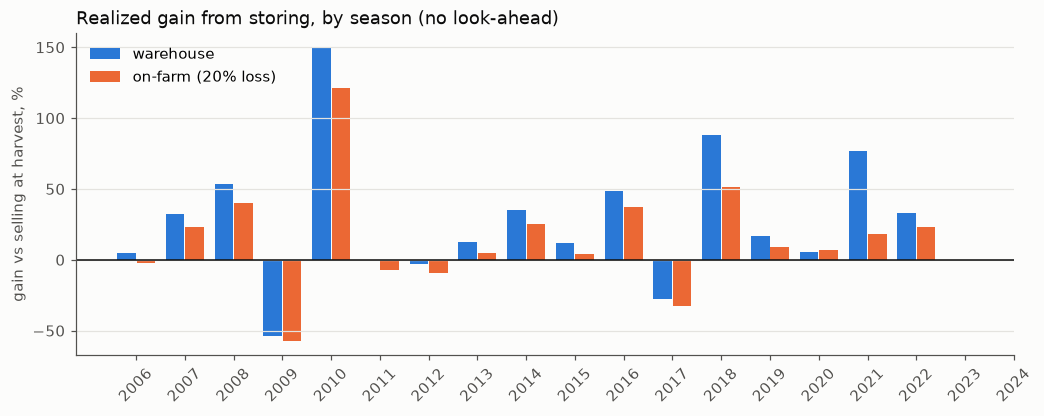

In [20]:
brng = np.random.default_rng(2026)
summ = []
for name in SC_BT:
    x = bt[f"{name}: gain"].dropna()
    reps = [brng.choice(x.values, len(x)).mean() for _ in range(5000)]
    ex = x.drop([2021, 2022], errors="ignore")                 # seasons starting Dec 2021 / Dec 2022
    summ.append({"scenario": name, "seasons": len(x), "mean gain": x.mean(), "median": x.median(),
                 "worst": x.min(), "seasons storing won": f"{int((x > 0).sum())}/{len(x)}",
                 "95% CI low (bootstrap)": np.quantile(reps, .025), "95% CI high": np.quantile(reps, .975),
                 "mean excl. 2022–23 spike seasons": ex.mean()})
display(pd.DataFrame(summ).set_index("scenario").round(3))

fig, ax = plt.subplots(figsize=(11, 3.8))
xs = np.arange(len(bt))
for (name, col), off in zip([("warehouse", BLUE), ("on-farm (20% loss)", ORANGE)], [-0.2, 0.2]):
    ax.bar(xs + off, 100 * bt[f"{name}: gain"].values, width=0.38, color=col, label=name)
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(xs, bt.index, rotation=45)
ax.set_ylabel("gain vs selling at harvest, %")
ax.set_title("Realized gain from storing, by season (no look-ahead)", loc="left", color=INK)
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.show()

**Testing a price-dependent rule on the data.** The model says the timing depends only on the
calendar. Does the data disagree? Test a simple rule: sell *before* the planned month as soon as
the price is at least $(1+X)$ times the typical seasonal path from December. $X$ is chosen each
season from {10%, 20%, 30%, 50%, never} by what would have worked best in **earlier seasons
only** (from 2012 on, so that at least 5 earlier seasons exist), then applied to the next season.

In [21]:
GRID = [0.1, 0.2, 0.3, 0.5, np.inf]
thr_rows = []
for name, c in SC_BT.items():
    for y in range(2012, 2026):
        if np.isnan(season_gain(y, c)[0]):
            continue
        past = {X: np.nanmean([season_gain(yy, c, X)[0] for yy in range(2007, y)]) for X in GRID}
        Xb = max(past, key=past.get)
        thr_rows.append({"scenario": name, "season (Dec start)": y - 1, "chosen X": Xb,
                         "threshold rule": season_gain(y, c, Xb)[0], "hold to planned month": season_gain(y, c)[0]})
thr = pd.DataFrame(thr_rows)
display(thr.groupby("scenario")[["threshold rule", "hold to planned month"]].mean().round(3))
print("threshold chosen (X):", thr["chosen X"].value_counts().to_dict())

,threshold rule,hold to planned month
scenario,,
on-farm (20% loss),0.109,0.109
warehouse,0.247,0.247


threshold chosen (X): {inf: 24}


**Reading.** Storing beat selling at harvest in most seasons, and the warehouse's average
gain is positive with a confidence interval that excludes zero; on-farm storage gains less and
its interval includes zero — losses eat much of the seasonal rise. The 2022–23 spike seasons
raise the average but do not create it (the "excl." column). The bad seasons (starting Dec 2009
and Dec 2017) were real losses of 28–57%: storage pays on average, not every year.

The price-dependent rule never chose to sell early: in every season, "never sell early" had
worked best in the earlier seasons. Selling early because the price had run ahead of its usual
path did not pay historically — consistent with the model's calendar rule.

## Step 9 — How sensitive is the answer to the costs?

Recompute the gain from storing — both the model value (Step 6) and the historical average
(Step 8) — while varying one cost at a time: the on-farm loss rate and the interest rate. The
**break-even** point is where storing stops paying. (σ is not varied: it does not change the
selling rule, and affects the value only through the σ²/2 term.)

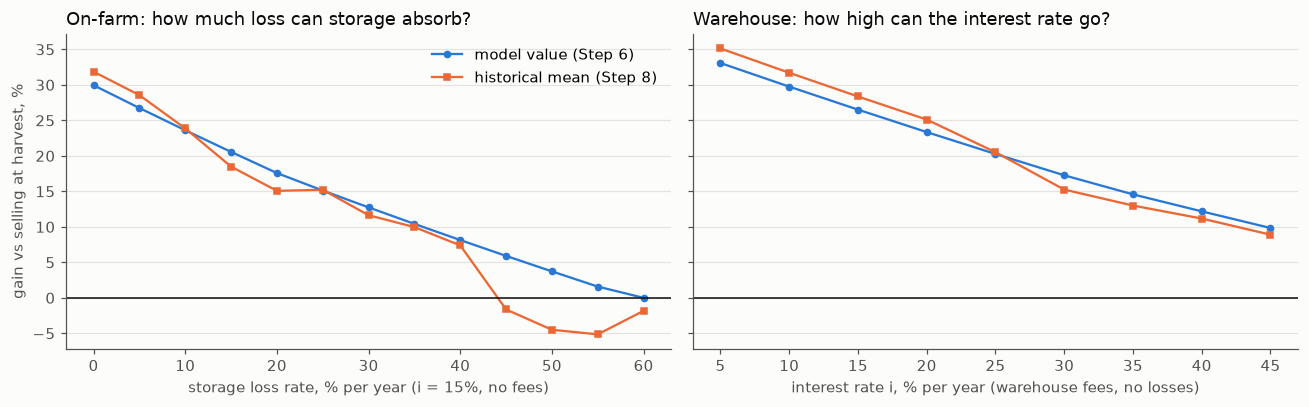

break-even on-farm loss rate (model)            60.0
break-even on-farm loss rate (history)          45.0
break-even warehouse interest rate (model)      68.0
break-even warehouse interest rate (history)    53.0
Name: % per year, dtype: float64

In [22]:
def model_gain(fee, loss, r_, once):
    return store_value(fee, loss, r_=r_)[0] - 1 - once

def hist_gain(fee, loss, r_, once):
    return np.nanmean([season_gain(y, dict(fee=fee, loss=loss, once=once), r_=r_)[0] for y in range(2007, 2026)])

losses = np.linspace(0, 0.6, 13)
rates = np.linspace(0.05, 0.45, 9)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, xs_, f_model, f_hist, xl in [
        (axes[0], losses, lambda x: model_gain(0, x, .15, 0), lambda x: hist_gain(0, x, .15, 0),
         "storage loss rate, % per year (i = 15%, no fees)"),
        (axes[1], rates, lambda x: model_gain(.03, 0, x, .015), lambda x: hist_gain(.03, 0, x, .015),
         "interest rate i, % per year (warehouse fees, no losses)")]:
    ax.plot(100 * xs_, [100 * f_model(x) for x in xs_], "o-", color=BLUE, ms=4, label="model value (Step 6)")
    ax.plot(100 * xs_, [100 * f_hist(x) for x in xs_], "s-", color=ORANGE, ms=4, label="historical mean (Step 8)")
    ax.axhline(0, color=INK, lw=1); ax.set_xlabel(xl); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("gain vs selling at harvest, %"); axes[0].legend(frameon=False)
axes[0].set_title("On-farm: how much loss can storage absorb?", loc="left", color=INK)
axes[1].set_title("Warehouse: how high can the interest rate go?", loc="left", color=INK)
plt.tight_layout(); plt.show()

def first_zero(f, grid):
    # smallest cost on the grid at which the gain is no longer positive (storage stops paying)
    for x in grid:
        if f(x) <= 1e-6:
            return x
    return np.nan

fine_loss, fine_rate = np.arange(0, 1.001, 0.01), np.arange(0, 1.001, 0.01)
be = {
    "break-even on-farm loss rate (model)": first_zero(lambda x: model_gain(0, x, .15, 0), fine_loss),
    "break-even on-farm loss rate (history)": first_zero(lambda x: hist_gain(0, x, .15, 0), fine_loss),
    "break-even warehouse interest rate (model)": first_zero(lambda x: model_gain(.03, 0, x, .015), fine_rate),
    "break-even warehouse interest rate (history)": first_zero(lambda x: hist_gain(.03, 0, x, .015), fine_rate),
}
pd.Series(be).mul(100).round(1).rename("% per year")

**Reading.** The break-even values are the most practical output: storing keeps paying until
the loss rate or the interest rate reaches the printed levels. A certified warehouse removes
losses, so its margin is limited by the interest rate (break-even ≈ 53–68%/yr, far above Kenyan
lending rates of ≈ 15%). On-farm storage is limited by losses: break-even ≈ 45–60%/yr, so typical
Kenyan on-farm losses of 20–36%/yr leave a positive but much thinner margin. The historical
break-evens are lower than the model's because real seasons include the large losing years.

## Conclusions

* **The seasonal cycle is real and stable** (Step 2): Eldoret prices rise from the
  December–January harvest to a May–July peak in 15 of 17 seasons; the typical rise to June is
  ≈ 34%.
* **The seasonal curve predicts** (Step 5): three months ahead it beats "no change" on data it
  has not seen.
* **Value of storing** (Step 6): ≈ +27% of the December price in a certified warehouse at a 15%
  interest rate, ≈ +18% on-farm at 20%/yr losses; the best time to sell is the end of June.
* **The decision is a calendar rule** (Step 6): because the payoff and all costs are proportional
  to the price, the optimal rule is a fixed sale month, equal to the cost-of-carry inequality
  checked month by month. A price-dependent rule tested on past seasons (Step 8) never improved
  on it.
* **On real seasons** (Step 8): warehouse storage gained ≈ +28% on average (95% interval
  7–52%) and won 13 of 17 seasons, but lost 28–57% in the two worst seasons; on-farm storage
  gained about half as much, and its average is not clearly above zero (−2% to 33%).
* **Break-evens** (Step 9): warehouse storage keeps paying up to an interest rate of ≈ 53%
  (history) to 68% (model); on-farm storage up to a loss rate of ≈ 45–60%/yr.

**Limitations.** One wholesale market (Eldoret), not farm-gate or agriBORA prices; monthly data
with 9 missing months; only 17 seasons; costs from 2020–26 sources applied to 2006–25; the farmer
is assumed to care only about the average outcome (no extra penalty for the bad years); the fat
tails, volatility clustering and year-to-year reversal found in Step 4 are not in the model — the
Step 8 replay on real prices is the check against them; no modelling of government interventions
(import-duty waivers, cereal-board purchases).